# Análise e Visualização de Dados

**João Victor Uchôa**

Usei dados de clima de Brasília do INMET de 2014 até 2023.


## começo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("clima_brasilia.csv")
df.head()

,datetime,ano_arquivo,temperatura,umidade,precipitacao
0,2014-01-01 00:00:00,2014.0,21.2,82.0,0.0
1,2014-01-01 01:00:00,2014.0,20.3,91.0,0.0
2,2014-01-01 02:00:00,2014.0,19.9,91.0,0.0
3,2014-01-01 03:00:00,2014.0,19.9,90.0,0.0
4,2014-01-01 04:00:00,2014.0,19.4,95.0,0.0


In [ ]:
df.shape

(87582, 5)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 87582 entries, 0 to 87581
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   datetime      87582 non-null  object 
 1   ano_arquivo   87582 non-null  float64
 2   temperatura   87582 non-null  float64
 3   umidade       87582 non-null  float64
 4   precipitacao  87582 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.3+ MB


In [ ]:
df.describe()

,ano_arquivo,temperatura,umidade,precipitacao
count,87582.000000,87582.000000,87582.000000,87582.000000
mean,2018.499623,21.587269,62.130358,-2.237448
std,2.872683,3.930635,153.563581,154.822196
min,2014.000000,5.300000,-9999.000000,-9999.000000
25%,2016.000000,18.900000,48.000000,0.000000
50%,2019.000000,21.100000,66.000000,0.000000
75%,2021.000000,24.400000,83.000000,0.000000
max,2023.000000,35.500000,100.000000,62.800000


No `describe()` acima a umidade tem desvio padrão muito alto e mínimo de `-9999`. Isso não é um valor real de umidade: é o código que o INMET usa para registro sem leitura. Trato esses casos na seção de dados faltantes, e por isso as estatísticas dessa célula ainda estão distorcidas.

## repetidos

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum()

datetime        0
ano_arquivo     0
temperatura     0
umidade         0
precipitacao    0
dtype: int64

## dados faltantes

In [ ]:
colunas = ["temperatura", "umidade", "precipitacao"]
(df[colunas] == -9999).sum()

temperatura      0
umidade         20
precipitacao    21
dtype: int64

In [ ]:
df[colunas] = df[colunas].replace(-9999, np.nan)
df[colunas].isna().sum()

temperatura      0
umidade         20
precipitacao    21
dtype: int64

In [ ]:
df[df[colunas].isna().any(axis=1)].head()

,datetime,ano_arquivo,temperatura,umidade,precipitacao
9076,2015-01-14 04:00:00,2015.0,21.011111,NaN,NaN
9077,2015-01-14 05:00:00,2015.0,21.522222,NaN,NaN
9078,2015-01-14 06:00:00,2015.0,22.033333,NaN,NaN
9079,2015-01-14 07:00:00,2015.0,22.544444,NaN,NaN
9080,2015-01-14 08:00:00,2015.0,23.055556,NaN,NaN


Tem poucos dados faltantes. Não vou inventar valores, então deixei como `NaN`.

## distribuição

In [ ]:
df[colunas].describe().round(2)

,temperatura,umidade,precipitacao
count,87582.00,87562.00,87561.00
mean,21.59,64.43,0.16
std,3.93,21.46,1.37
min,5.30,10.00,0.00
25%,18.90,48.00,0.00
50%,21.10,66.00,0.00
75%,24.40,83.00,0.00
max,35.50,100.00,62.80


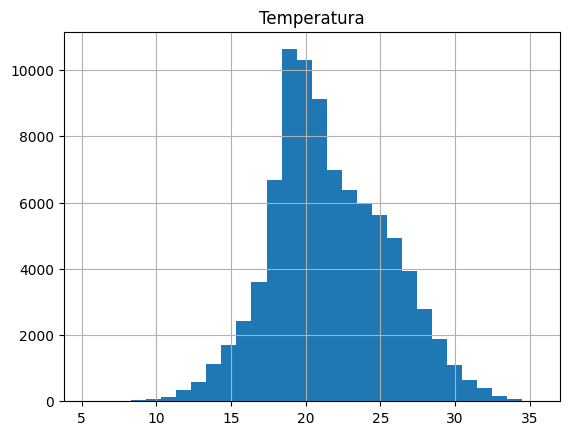

In [ ]:
df["temperatura"].hist(bins=30)
plt.title("Temperatura")
plt.show()

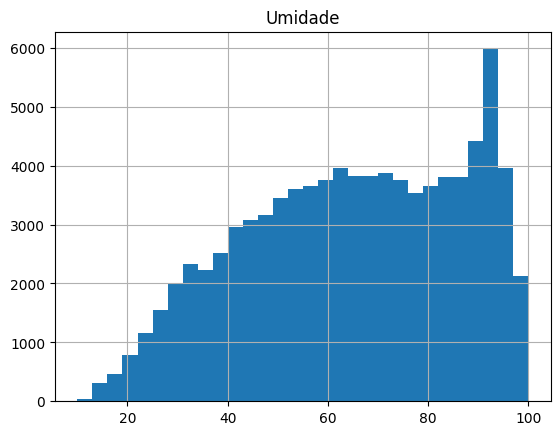

In [ ]:
df["umidade"].hist(bins=30)
plt.title("Umidade")
plt.show()

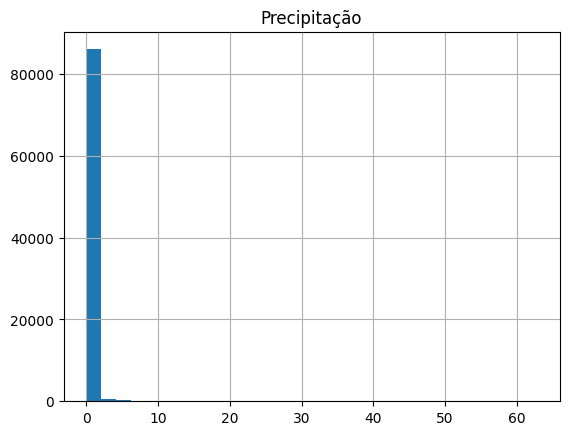

In [ ]:
df["precipitacao"].hist(bins=30)
plt.title("Precipitação")
plt.show()

A temperatura ficou mais concentrada. A precipitação ficou muito perto de zero na maior parte dos registros.

## outliers

In [ ]:
for coluna in colunas:
    q1 = df[coluna].quantile(0.25)
    q3 = df[coluna].quantile(0.75)
    iqr = q3 - q1
    limite1 = q1 - 1.5 * iqr
    limite2 = q3 + 1.5 * iqr
    qtd = ((df[coluna] < limite1) | (df[coluna] > limite2)).sum()
    print(coluna, qtd)

temperatura 303
umidade 0
precipitacao 5383


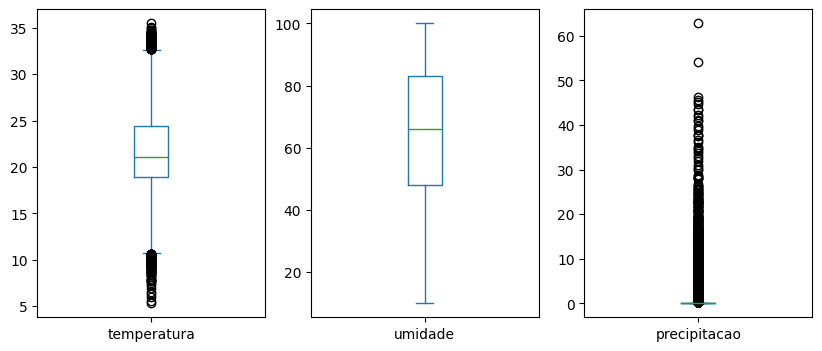

In [ ]:
df[colunas].plot(kind="box", subplots=True, layout=(1,3), figsize=(10,4))
plt.show()

Não removi os valores extremos. Como são dados de clima, eles podem ser valores reais.

Vale notar que o IQR não funciona bem para a precipitação. Como chove em poucas horas do dia, o 1º e o 3º quartis são iguais a zero e o IQR fica praticamente nulo. Com isso, qualquer hora em que choveu acaba sendo marcada como outlier, o que explica os casos. Ou seja, o método está apontando "choveu" e não um valor anormal, então esse número não deve ser lido como erro de medição.

## data e hora

In [ ]:
df["datetime"] = pd.to_datetime(df["datetime"])
df["ano"] = df["datetime"].dt.year
df["mes"] = df["datetime"].dt.month
df["hora"] = df["datetime"].dt.hour
df.head()

,datetime,ano_arquivo,temperatura,umidade,precipitacao,ano,mes,hora
0,2014-01-01 00:00:00,2014.0,21.2,82.0,0.0,2014,1,0
1,2014-01-01 01:00:00,2014.0,20.3,91.0,0.0,2014,1,1
2,2014-01-01 02:00:00,2014.0,19.9,91.0,0.0,2014,1,2
3,2014-01-01 03:00:00,2014.0,19.9,90.0,0.0,2014,1,3
4,2014-01-01 04:00:00,2014.0,19.4,95.0,0.0,2014,1,4


In [ ]:
# confere se o ano do registro bate com o ano do arquivo de origem
(df["ano"] != df["ano_arquivo"]).sum()

Fiz essa checagem porque arquivos anuais do INMET às vezes trazem registros da virada do ano. Se o resultado for zero, os anos estão consistentes.

## temperatura por hora

A temperatura muda durante o dia?

In [ ]:
temp_hora = df.groupby("hora")["temperatura"].mean()
temp_hora

hora
0     20.856755
1     20.312798
2     19.863552
3     19.406851
4     18.940398
5     18.523465
6     18.175454
7     17.909138
8     17.638804
9     17.498510
10    18.304305
11    20.291422
12    21.800986
13    23.205023
14    24.399114
15    25.248328
16    25.782963
17    26.031164
18    26.031481
19    25.677944
20    24.950318
21    23.535839
22    22.224031
23    21.472308
Name: temperatura, dtype: float64

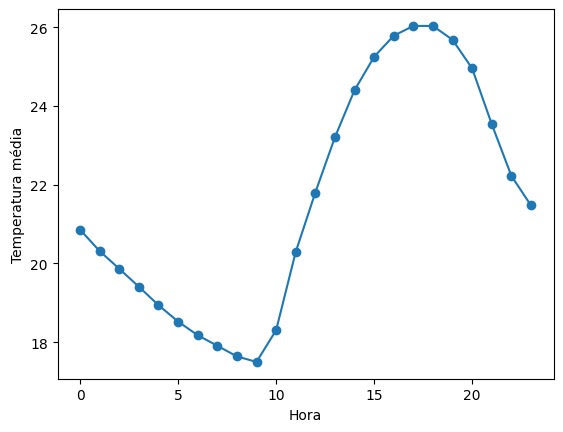

In [ ]:
plt.plot(temp_hora.index, temp_hora.values, marker="o")
plt.xlabel("Hora")
plt.ylabel("Temperatura média")
plt.show()

A temperatura vai aumentando durante o dia e fica maior no fim da tarde.

## estação do ano

In [ ]:
def estacao(mes):
    if mes in [12, 1, 2]:
        return "Verão"
    if mes in [3, 4, 5]:
        return "Outono"
    if mes in [6, 7, 8]:
        return "Inverno"
    return "Primavera"

df["estacao"] = df["mes"].apply(estacao)
df.groupby("estacao")["temperatura"].mean().round(2)

estacao
Inverno      20.01
Outono       21.17
Primavera    23.23
Verão        21.96
Name: temperatura, dtype: float64

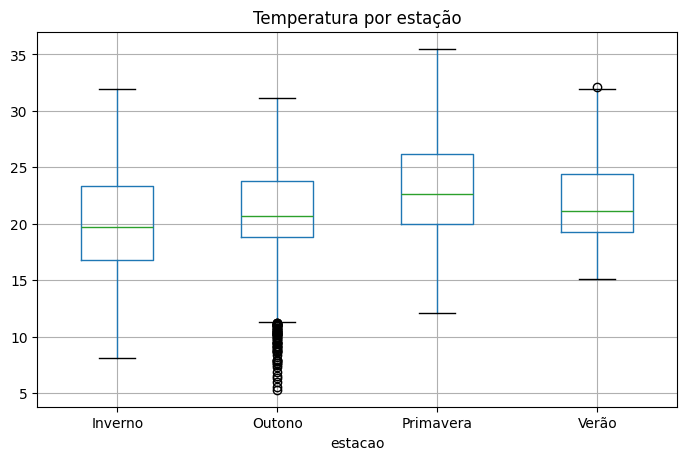

In [ ]:
df.boxplot(column="temperatura", by="estacao", figsize=(8,5))
plt.title("Temperatura por estação")
plt.suptitle("")
plt.show()

O inverno teve as menores médias e a primavera as maiores.

## temperatura e umidade

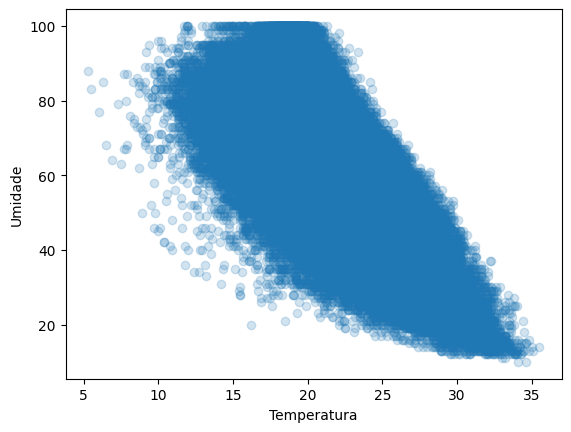

In [ ]:
plt.scatter(df["temperatura"], df["umidade"], alpha=0.2)
plt.xlabel("Temperatura")
plt.ylabel("Umidade")
plt.show()

In [ ]:
df[["temperatura", "umidade"]].corr()

,temperatura,umidade
temperatura,1.000000,-0.679433
umidade,-0.679433,1.000000


A correlação entre temperatura e umidade ficou negativa. Quando a temperatura aumenta, a umidade tende a diminuir.

## chuva por ano

In [ ]:
chuva_ano = df.groupby("ano")["precipitacao"].sum()
chuva_ano.round(1)

ano
2014    1474.8
2015    1087.6
2016    1140.8
2017    1292.0
2018    1702.0
2019    1369.4
2020    1576.6
2021    2023.2
2022    1356.4
2023     996.0
Name: precipitacao, dtype: float64

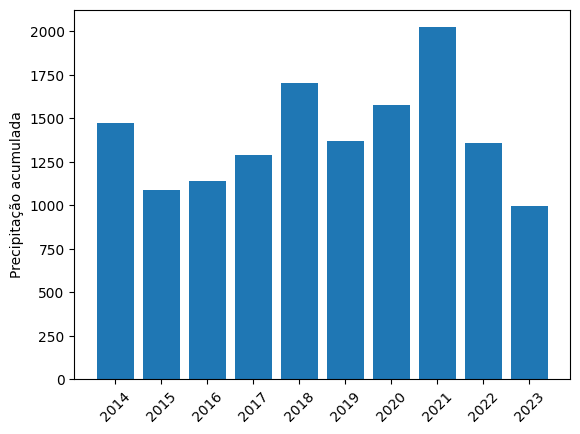

In [ ]:
plt.bar(chuva_ano.index.astype(str), chuva_ano.values)
plt.xticks(rotation=45)
plt.ylabel("Precipitação acumulada")
plt.show()

Os anos tiveram valores diferentes. 2021 foi um dos anos com mais chuva e 2023 teve menos.

## correlação

In [ ]:
correlacao = df[colunas].corr()
correlacao.round(2)

,temperatura,umidade,precipitacao
temperatura,1.00,-0.68,-0.07
umidade,-0.68,1.00,0.15
precipitacao,-0.07,0.15,1.00


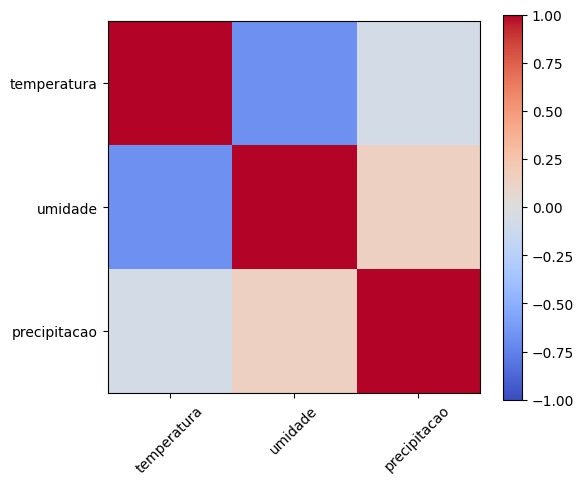

In [ ]:
plt.figure(figsize=(6,5))
plt.imshow(correlacao, cmap="coolwarm", vmin=-1, vmax=1)
plt.xticks(range(len(colunas)), colunas, rotation=45)
plt.yticks(range(len(colunas)), colunas)
plt.colorbar()
plt.show()

A relação mais forte foi entre temperatura e umidade.

## temperatura e umidade por estação

In [ ]:
for nome in ["Verão", "Outono", "Inverno", "Primavera"]:
    parte = df[df["estacao"] == nome]
    plt.scatter(parte["temperatura"], parte["umidade"], alpha=0.2, s=8, label=nome)

plt.xlabel("Temperatura")
plt.ylabel("Umidade")
plt.legend()
plt.show()

Separando por estação, a relação negativa entre temperatura e umidade aparece em todas elas, mas as nuvens de pontos ficam em regiões diferentes: o inverno se concentra na parte de baixo (umidade menor) e o verão na parte de cima. Os pontos mais afastados podem ser valores reais, então preferi não apagar nenhum.

## conclusão

- A base tem muitos registros por hora.
- Os `-9999` foram tratados como `NaN`.
- A precipitação ficou bem concentrada em zero.
- A temperatura varia ao longo do dia.
- Temperatura e umidade tiveram relação negativa.

## o que não fiz

não fiz os testes bivariados porque essa parte era opcional na atividade.

não encontrei linhas repetidas, então não precisei remover nenhuma.

encontrei alguns valores extremos, mas decidi não remover porque eles podem representar valores reais do clima.

## uso de IA
usei o chatgpt para tirar algumas dúvidas durante a atividade e entender melhor o que eu tinha que fazer em cada etapa.

1. to começando a estudar análise e visualização de dados. o que eu devo olhar primeiro quando recebo um dataset de clima?

2. no meu dataset tem vários valores -9999. o que isso significa e o que eu faço com esses valores?

3. como eu posso olhar a distribuição de temperatura, umidade e precipitação de um jeito simples?

4. como eu vejo se tem valores muito fora do padrão usando o iqr?

5. se aparecerem valores extremos, como eu sei se são erros ou se podem ser valores reais? vale a pena tirar eles?

6. como eu posso analisar a temperatura de acordo com a hora do dia e fazer um gráfico simples?

7. como eu posso comparar a temperatura nas diferentes estações do ano e explicar o resultado?

8. quero ver se temperatura e umidade têm alguma relação. qual gráfico posso usar e como eu posso interpretar sem falar que uma causa a outra?

9. os testes bivariados eram opcionais, então posso não fazer essa parte? também não encontrei linhas repetidas e não tirei os valores extremos. como posso explicar essas decisões?